In [1]:
import pandas as pd
df=pd.read_csv('/home/elena/esercizi/2026-datathon-httparchive/php_presence2026.csv')
df.head()

,client,total_origins,php_origins,pct_php
0,mobile,15470430,7319064,47.31
1,desktop,11359288,5441378,47.90


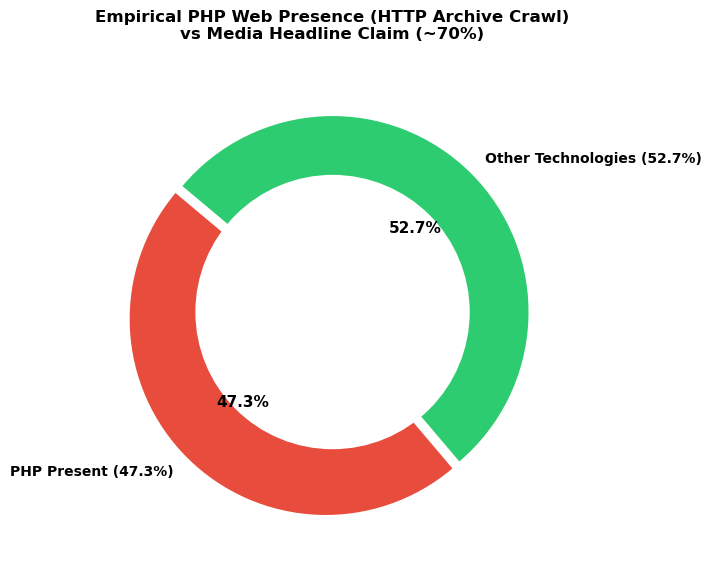

In [4]:
import matplotlib.pyplot as plt
import pandas as pd

# ----------------------------------------------------
# Opzione A: Se vuoi usare i dati del tuo DataFrame `df` importato da BigQuery
# Sostituisci 'desktop' o 'mobile' a seconda di quale riga vuoi rappresentare
# ----------------------------------------------------
# php_pct = df[df['client'] == 'desktop']['pct_php'].values[0]

# Opzione B: Usare direttamente la media aggregata (~52% PHP vs ~48% Altro)
php_pct = 47.31
other_pct = 100 - php_pct

# Valori e etichette per il grafico
labels = [f'PHP Present ({php_pct:.1f}%)', f'Other Technologies ({other_pct:.1f}%)']
sizes = [php_pct, other_pct]
colors = ['#e74c3c', '#2ecc71']

# Creazione del grafico Donut Chart (a ciambella)
fig, ax = plt.subplots(figsize=(7, 7))

wedges, texts, autotexts = ax.pie(
    sizes, 
    labels=labels, 
    autopct='%1.1f%%',
    startangle=140, 
    colors=colors, 
    explode=(0.05, 0),
    textprops=dict(color="black", fontweight='bold')
)

# Cerchio centrale per creare l'effetto ciambella
centre_circle = plt.Circle((0, 0), 0.70, fc='white')
fig.gca().add_artist(centre_circle)

# Personalizzazione dei testi e titolo
plt.setp(autotexts, size=11, weight="bold")
plt.title('Empirical PHP Web Presence (HTTP Archive Crawl)\nvs Media Headline Claim (~70%)', fontsize=12, fontweight='bold', pad=20)

plt.tight_layout()

# Salva l'immagine sul tuo PC per incollaria nel Google Doc
plt.savefig('php_web_presence_donut_2026.png', dpi=300, bbox_inches='tight')
plt.show()

In [8]:
df_version_2026=pd.read_csv('/home/elena/esercizi/2026-datathon-httparchive/version_disclosure2026.csv')
df_version_2026.head()

,client,php_version,origins
0,mobile,8.3.33,382935
1,mobile,7.4.33,372094
2,mobile,8.2.33,286464
3,desktop,7.4.33,257613
4,desktop,8.3.33,254675


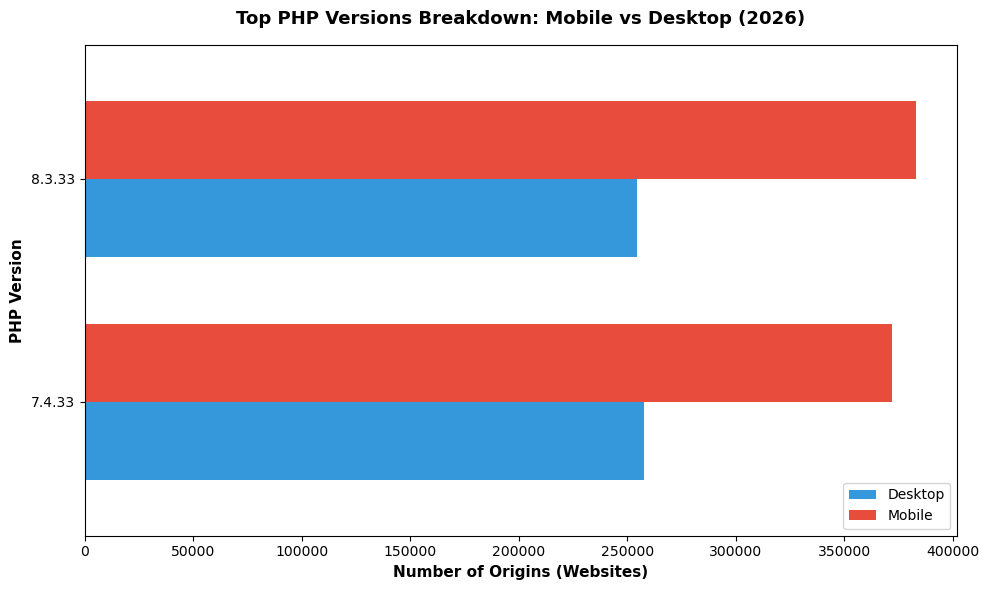

In [14]:
import matplotlib.pyplot as plt
import pandas as pd

# Carica il CSV (assicurati che il nome del file corrisponda al tuo)
# Se usi direttamente i dati nel DataFrame:
data = {
    'client': ['mobile', 'mobile', 'mobile', 'desktop', 'desktop'],
    'php_version': ['8.3.33', '7.4.33', '8.2.33', '7.4.33', '8.3.33'],
    'origins': [382935, 372094, 286464, 257613, 254675]
}
df = pd.DataFrame(data)

# OPZIONE: Filtriamo per tenere solo le versioni che compaiono 
# sia su mobile che su desktop (evitando così barre singole o "buchi")
version_counts = df.groupby('php_version')['client'].nunique()
valid_versions = version_counts[version_counts == 2].index
df_filtered = df[df['php_version'].isin(valid_versions)]

# Se invece vuoi mostrare TUTTE quelle presenti nel CSV riempiendo a 0 i mancanti:
# df_filtered = df

# Creazione della tabella pivot
pivot_df = df_filtered.pivot(index='php_version', columns='client', values='origins').fillna(0)

# Ordiniamo per totale di siti (origins) in modo crescente per il grafico a barre orizzontali
pivot_df['total'] = pivot_df.sum(axis=1)
pivot_df = pivot_df.sort_values('total', ascending=True)
pivot_df = pivot_df.drop(columns='total')

fig, ax = plt.subplots(figsize=(10, 6))

# Grafico a barre orizzontali
pivot_df.plot(kind='barh', ax=ax, color=['#3498db', '#e74c3c'], width=0.7)

ax.set_ylabel('PHP Version', fontweight='bold', fontsize=11)
ax.set_xlabel('Number of Origins (Websites)', fontweight='bold', fontsize=11)
ax.set_title('Top PHP Versions Breakdown: Mobile vs Desktop (2026)', fontsize=13, fontweight='bold', pad=15)
ax.legend(['Desktop', 'Mobile'], loc='lower right')

plt.tight_layout()

# Salva l'immagine ad alta risoluzione
plt.savefig('php_versions_breakdown_clean2026.png', dpi=300, bbox_inches='tight', transparent=True)
plt.show()